In [2]:
'''LOGISTIC REGRESSION
1. Data Exploration:
a. Load the dataset and perform exploratory data analysis (EDA).
b. Examine the features, their types, and summary statistics.
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.
2. Data Preprocessing:
a. Handle missing values (e.g., imputation).
b. Encode categorical variables.
3. Model Building:
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).
b. Train the model using the training data.
4. Model Evaluation:
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.
5. Interpretation:
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).
6. Deployment with Streamlit:
In this task, you will deploy your logistic regression model using Streamlit. The deployment can be done locally or online via Streamlit Share. Your task includes creating a Streamlit app in Python that involves loading your trained model and setting up user inputs for predictions. 
'''

'LOGISTIC REGRESSION\n1. Data Exploration:\na. Load the dataset and perform exploratory data analysis (EDA).\nb. Examine the features, their types, and summary statistics.\nc. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.\nAnalyze any patterns or correlations observed in the data.\n2. Data Preprocessing:\na. Handle missing values (e.g., imputation).\nb. Encode categorical variables.\n3. Model Building:\na. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).\nb. Train the model using the training data.\n4. Model Evaluation:\na. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.\nVisualize the ROC curve.\n5. Interpretation:\na. Interpret the coefficients of the logistic regression model.\nb. Discuss the significance of features in predicting the target variable (survival probability in this case).\n6

In [3]:
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [4]:
'''1. Data Exploration:
a. Load the dataset and perform exploratory data analysis (EDA).
b. Examine the features, their types, and summary statistics.
c. Create visualizations such as histograms, box plots, or pair plots to visualize the distributions and relationships between features.
Analyze any patterns or correlations observed in the data.'''

import pandas as pd
df = pd.read_csv("diabetes.csv")
df.head()


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [5]:
df.shape

(768, 9)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 9 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pregnancies               768 non-null    int64  
 1   Glucose                   768 non-null    int64  
 2   BloodPressure             768 non-null    int64  
 3   SkinThickness             768 non-null    int64  
 4   Insulin                   768 non-null    int64  
 5   BMI                       768 non-null    float64
 6   DiabetesPedigreeFunction  768 non-null    float64
 7   Age                       768 non-null    int64  
 8   Outcome                   768 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB


In [7]:
df.describe()

,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000,768.000000
mean,3.845052,120.894531,69.105469,20.536458,79.799479,31.992578,0.471876,33.240885,0.348958
std,3.369578,31.972618,19.355807,15.952218,115.244002,7.884160,0.331329,11.760232,0.476951
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243750,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,30.500000,32.000000,0.372500,29.000000,0.000000
75%,6.000000,140.250000,80.000000,32.000000,127.250000,36.600000,0.626250,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [8]:
print(df.isnull().sum())

Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64


In [9]:
df["Outcome"].value_counts()

Outcome
0    500
1    268
Name: count, dtype: int64

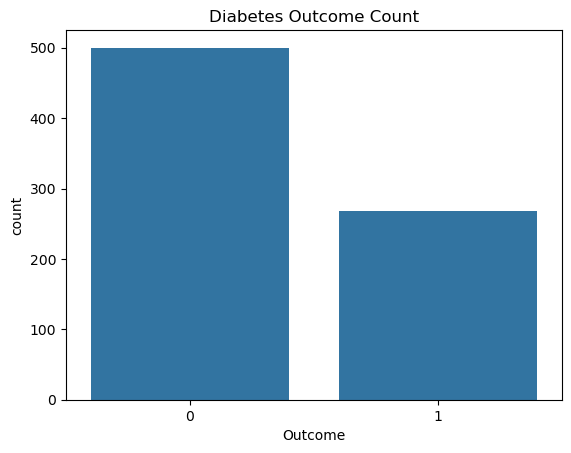

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.countplot(data=df, x="Outcome")
plt.title("Diabetes Outcome Count")
plt.show()

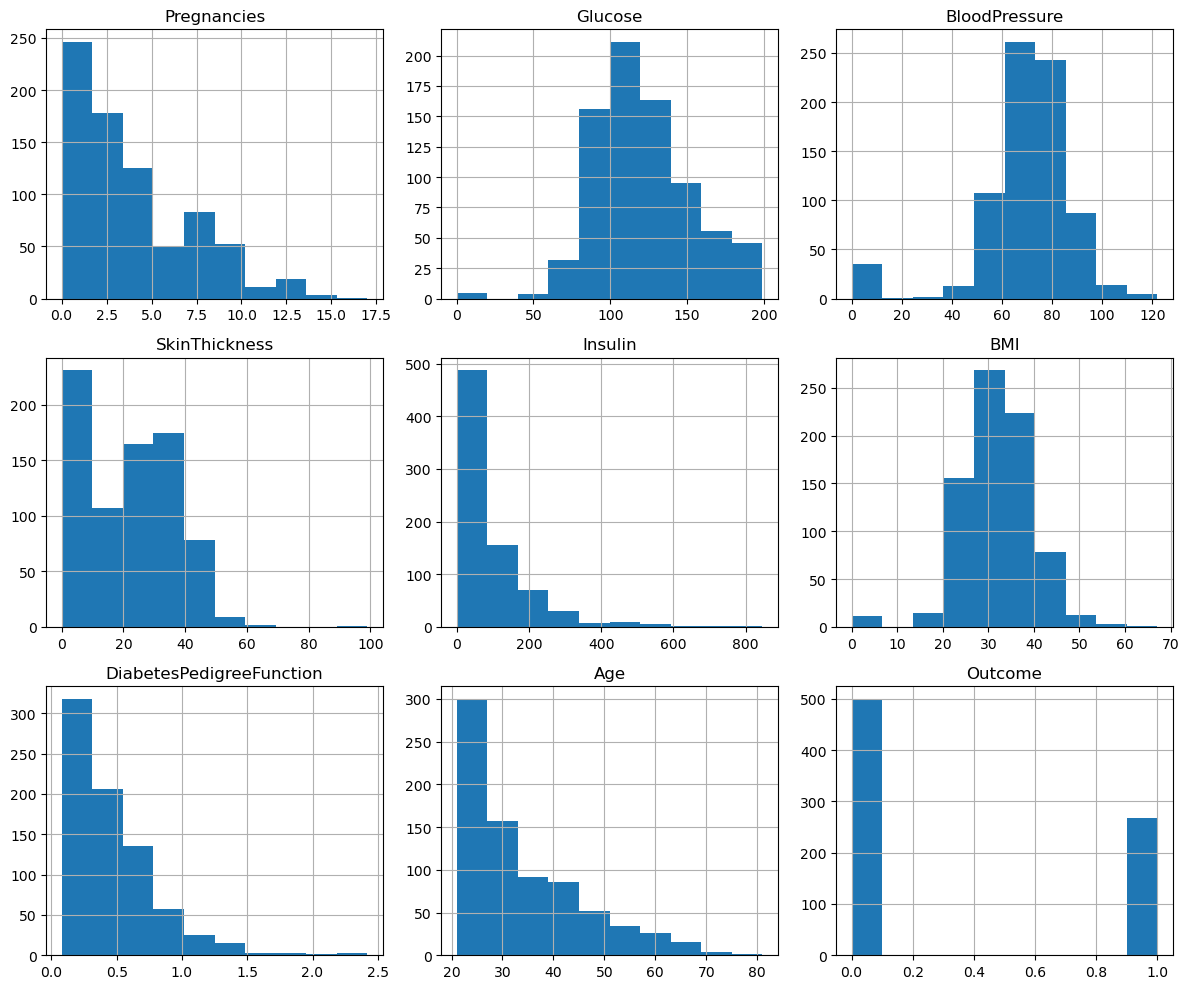

In [11]:
# Histograms
df.hist(figsize=(12, 10))
plt.tight_layout()
plt.show()

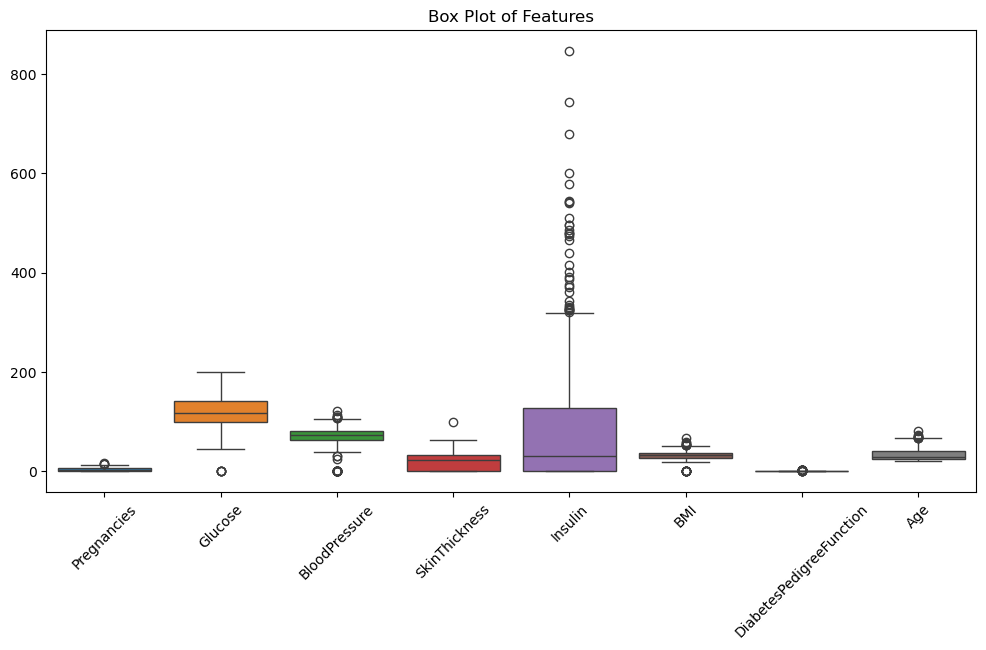

In [12]:
# Box plots
plt.figure(figsize=(12, 6))
sns.boxplot(data=df.drop(columns=["Outcome"]))
plt.xticks(rotation=45)
plt.title("Box Plot of Features")
plt.show()

In [13]:
'''2. Data Preprocessing:
a. Handle missing values (e.g., imputation).
b. Encode categorical variables.'''

import numpy as np
import joblib

from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

zero_cols = [
    "Glucose", "BloodPressure", "SkinThickness",
    "Insulin", "BMI"]

X[zero_cols] = X[zero_cols].replace(0, np.nan)


In [14]:
'''3. Model Building:
a. Build a logistic regression model using appropriate libraries (e.g., scikit-learn).
b. Train the model using the training data.'''

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)


model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])


model.fit(X_train, y_train)

print("Model trained successfully!")
print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

joblib.dump(model, "diabetes_model.pkl")

print("Model saved successfully!")

Model trained successfully!
Training data: (614, 8)
Testing data: (154, 8)
Model saved successfully!


In [15]:
'''4. Model Evaluation:
a. Evaluate the performance of the model on the testing data using accuracy, precision, recall, F1-score, and ROC-AUC score.
Visualize the ROC curve.'''

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, classification_report,
    ConfusionMatrixDisplay, RocCurveDisplay
)

y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print("Accuracy:", round(accuracy_score(y_test, y_pred), 3))
print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:", round(recall_score(y_test, y_pred), 3))
print("F1 Score:", round(f1_score(y_test, y_pred), 3))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 3))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))


Accuracy: 0.708
Precision: 0.6
Recall: 0.5
F1 Score: 0.545
ROC-AUC: 0.813

Classification Report:
              precision    recall  f1-score   support

           0       0.75      0.82      0.78       100
           1       0.60      0.50      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



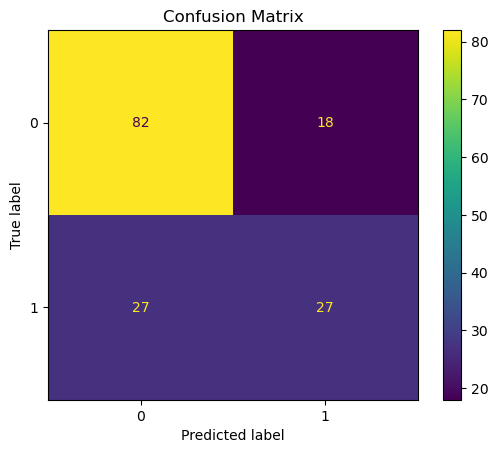

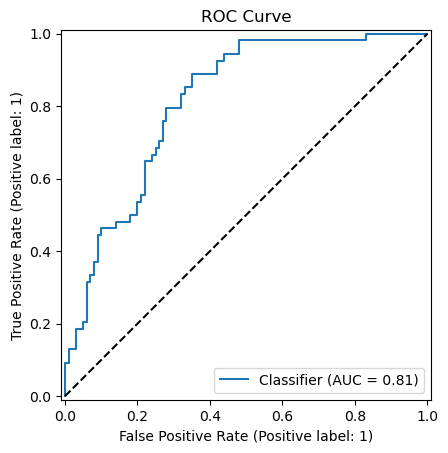

In [16]:
# Confusion matrix
ConfusionMatrixDisplay.from_predictions(y_test, y_pred)
plt.title("Confusion Matrix")
plt.show()

# ROC curve
RocCurveDisplay.from_predictions(y_test, y_prob)
plt.plot([0, 1], [0, 1], "k--")
plt.title("ROC Curve")
plt.show()

,Feature,Coefficient,Odds_Ratio
1,Glucose,1.182567,3.262739
5,BMI,0.688652,1.991030
0,Pregnancies,0.377446,1.458554
6,DiabetesPedigreeFunction,0.233337,1.262807
7,Age,0.147794,1.159274
3,SkinThickness,0.028321,1.028725
2,BloodPressure,-0.044111,0.956848
4,Insulin,-0.066119,0.936019


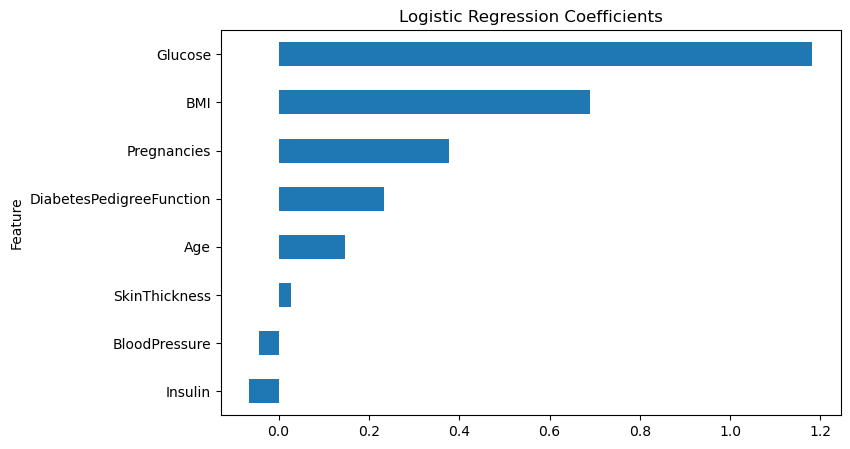

In [17]:
'''5. Interpretation:
a. Interpret the coefficients of the logistic regression model.
b. Discuss the significance of features in predicting the target variable (survival probability in this case).'''

classifier = model.named_steps["classifier"]

coef_df = pd.DataFrame({
    "Feature": X.columns,
    "Coefficient": classifier.coef_[0]
})

coef_df["Odds_Ratio"] = np.exp(coef_df["Coefficient"])

display(coef_df.sort_values(
    "Coefficient", ascending=False
))

coef_df.sort_values("Coefficient").plot(
    x="Feature", y="Coefficient",
    kind="barh", legend=False, figsize=(8, 5)
)

plt.title("Logistic Regression Coefficients")
plt.show()